# Interpolation

**Lecture 7 · Wednesday, 28 October 2026 · Notebook 2 of 2**

**Video 7C.** This notebook starts from a fresh kernel and does not depend on code run in `01_RootFinding.ipynb`.

**Question:** we know a relationship at a few input values. What value should we use **between** them? And can we still solve an equation when the only thing we have is such a table?

You will draw straight lines between known points, use `np.interp`, distinguish interpolation from making assumptions outside the table, and finally combine interpolation with a root-finder. This is **linear interpolation**, not regression or a causal estimate.

**Table of contents**<a id='toc0_'></a>
- 1. [A small income and spending table](#toc1_)
- 2. [Linear interpolation by hand](#toc2_)
- 3. [Use NumPy and plot the result](#toc3_)
- 4. [Check the inputs and the range](#toc4_)
- 5. [No formula? Solve on the interpolated table](#toc5_)
- 6. [What the approximation does and does not tell us](#toc6_)

<a id='video-7c'></a>
> **Start Video 7C**  
> Reuse arrays and plotting from Lectures 4–5. The only new numerical function is `np.interp`; the root-finder comes from Video 7B.

## 1. <a id='toc1_'></a>[A small income and spending table](#toc0_)

Suppose a toy household-spending relationship has been calculated at four monthly income levels. **These are invented teaching values**, not survey data. We know monthly consumption expenditure at these four inputs, but have not been given a formula between them.

| Monthly income (DKK) | Monthly consumption expenditure (DKK) |
| --- | --- |
| 10,000 | 9,000 |
| 15,000 | 12,500 |
| 20,000 | 15,000 |
| 25,000 | 17,000 |

The first entries in the arrays form one pair, the second entries another, and so on. We want an approximation at an income of **18,000 DKK**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize

income_known = np.array([10_000.0, 15_000.0, 20_000.0, 25_000.0])
consumption_known = np.array([9_000.0, 12_500.0, 15_000.0, 17_000.0])

## 2. <a id='toc2_'></a>[Linear interpolation by hand](#toc0_)

18,000 lies between **15,000 and 20,000**. First calculate how far it is from the lower income, as a fraction of that interval:

$$w=\frac{x-x_{\mathrm{low}}}{x_{\mathrm{high}}-x_{\mathrm{low}}}.$$

Then move the same fraction of the way between the two consumption values:

$$\widehat{y}=y_{\mathrm{low}}+w(y_{\mathrm{high}}-y_{\mathrm{low}}).$$

**In words:** start at the lower point and add the relevant fraction of the change to the upper point. Inside the interval, $w$ is between zero and one.

In [2]:
income_query = 18_000.0
weight = (income_query - 15_000.0)/(20_000.0 - 15_000.0)
consumption_manual = 12_500.0 + weight*(15_000.0 - 12_500.0)

print(f'Fraction of the way through the interval: {weight:.2f}')
print(f'Interpolated consumption: {consumption_manual:,.2f} DKK')

Fraction of the way through the interval: 0.60
Interpolated consumption: 14,000.00 DKK


## 3. <a id='toc3_'></a>[Use NumPy and plot the result](#toc0_)

NumPy can locate the relevant interval and do the calculation:

`np.interp(query, known_inputs, known_outputs)`

The **order matters**: query first, then the known x-values, then the corresponding y-values. Here income is the input and consumption is the output.

In [3]:
consumption_numpy = np.interp(income_query, income_known, consumption_known)

print(f'NumPy result: {consumption_numpy:,.2f} DKK')
print(f'Difference from the manual calculation: {consumption_numpy - consumption_manual:.6f}')

NumPy result: 14,000.00 DKK
Difference from the manual calculation: 0.000000


### Ask for several values at once

An array of queries produces an array of answers. NumPy handles each query; there is no need to write a loop for this calculation.

In [4]:
income_queries = np.array([12_000.0, 18_000.0, 23_000.0])
consumption_queries = np.interp(income_queries, income_known, consumption_known)

for income, consumption in zip(income_queries, consumption_queries):
    print(f'Income: {income:,.0f}; consumption: {consumption:,.2f} DKK')

Income: 12,000; consumption: 10,400.00 DKK
Income: 18,000; consumption: 14,000.00 DKK
Income: 23,000; consumption: 16,200.00 DKK


### A connected set of straight lines

The dots are supplied values; the line is the approximation **we chose** between them. More points on the plotting grid make the line look continuous, but do not add information to the original table.

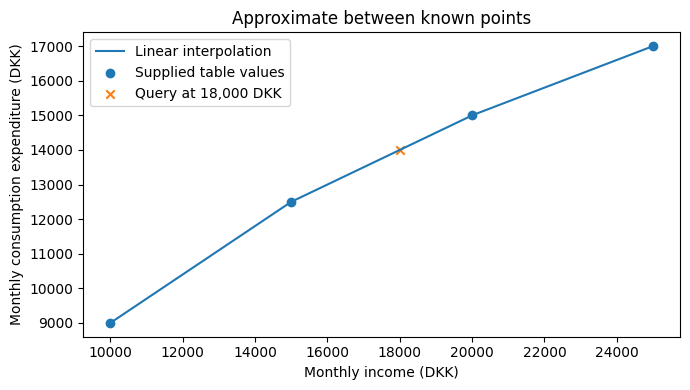

In [5]:
income_plot = np.linspace(income_known[0], income_known[-1], 200)
consumption_plot = np.interp(income_plot, income_known, consumption_known)

fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(1, 1, 1)
ax.plot(income_plot, consumption_plot, label='Linear interpolation')
ax.scatter(income_known, consumption_known, marker='o', label='Supplied table values')
ax.scatter(income_query, consumption_numpy, marker='x', label='Query at 18,000 DKK')
ax.set_xlabel('Monthly income (DKK)')
ax.set_ylabel('Monthly consumption expenditure (DKK)')
ax.set_title('Approximate between known points')
ax.legend()
fig.tight_layout()
plt.show()

## 4. <a id='toc4_'></a>[Check the inputs and the range](#toc0_)

Before interpolating, check that the input and output arrays have the **same length** and that the input values are **strictly increasing**. Each x-value must remain paired with its y-value. Never sort one array independently of the other.

In the next check, `np.diff` calculates neighbouring differences, and `np.all` asks whether every comparison is true. This is just an input check, not another interpolation method. The table must also contain usable, finite numbers; a `NaN` in the input grid is not acceptable.

In [6]:
print('Same length:', len(income_known) == len(consumption_known))
print('Inputs strictly increasing:', np.all(np.diff(income_known) > 0))
print('All inputs finite:', np.all(np.isfinite(income_known)))
print('All outputs finite:', np.all(np.isfinite(consumption_known)))

Same length: True
Inputs strictly increasing: True
All inputs finite: True
All outputs finite: True


### Outside the table is a different question

30,000 is **outside** the known income range. By default, `np.interp` returns the nearest endpoint value outside the range. It does **not** continue the final line with its slope.

**Pause and predict:** what will `np.interp` return at 30,000?

For this exercise, a safer choice is to return `np.nan` outside the table. `NaN` means “not a number”: it marks a value we are not supplying, rather than pretending that we know the relationship there.

In [7]:
print('Default result at 30,000:', np.interp(30_000.0, income_known, consumption_known))

outside_queries = np.array([8_000.0, 18_000.0, 30_000.0])
safe_values = np.interp(
    outside_queries,
    income_known,
    consumption_known,
    left=np.nan,
    right=np.nan
)
print('Values with an explicit range restriction:', safe_values)

Default result at 30,000: 17000.0
Values with an explicit range restriction: [   nan 14000.    nan]


## 5. <a id='toc5_'></a>[No formula? Solve on the interpolated table](#toc0_)

Now reverse the question: **at which income does consumption reach 16,000 DKK?** There is no formula to invert. But the interpolated table is a function of income, so we can use the recipe from Video 7B:

1. write the gap as a residual, $\text{consumption}(y) - 16{,}000$;
2. find a bracket **inside the table** where the residual changes sign;
3. call `brentq` and check the residual.

**Pause and predict:** 16,000 lies halfway between the table's 15,000 and 17,000. Which income do you expect?

In [8]:
target = 16_000.0


def consumption_from_table(income):
    return np.interp(income, income_known, consumption_known)


def consumption_gap(income):
    return consumption_from_table(income) - target


# a. check the bracket: the table's first and last income
a = income_known[0]
b = income_known[-1]
print('Gap at the ends of the table:', consumption_gap(a), consumption_gap(b))

# b. solve and check
result_income = optimize.root_scalar(consumption_gap, bracket=[a, b], method='brentq')
if not result_income.converged:
    raise RuntimeError(result_income.flag)

income_star = result_income.root
print(f'Income: {income_star:,.2f} DKK')
print(f'Consumption there: {consumption_from_table(income_star):,.2f} DKK')
print(f'Residual: {consumption_gap(income_star):.1e}')

Gap at the ends of the table: -7000.0 1000.0
Income: 22,500.00 DKK
Consumption there: 16,000.00 DKK
Residual: 0.0e+00


The answer, 22,500 DKK, sits halfway between 20,000 and 25,000, exactly as the hand check predicted. Keeping the bracket inside the table matters: outside it, `np.interp` would return flat endpoint values, not information.

The same pattern works for a market in which demand is known only from a table. That is the last question in class.

## 6. <a id='toc6_'></a>[What the approximation does and does not tell us](#toc0_)

Linear interpolation goes through the supplied points and uses straight segments between them. That does **not** mean the unknown true relationship is straight between the points. A denser plotting grid does not improve the approximation; only more (or better) table values do.

Nor does this illustrative table establish how an actual household would respond to a causal income change. We are learning a numerical operation, not estimating behaviour. A root of the interpolated function solves the **interpolated model**, not an unknown true curve.

### Three questions, three tools

| Question | Tool used in these lectures |
| --- | --- |
| Which feasible choice is best? | Optimization |
| At what input do two sides of an equation match? | Root-finding |
| What value do we use between known points? | Interpolation |

**Before class:** answer warm-up questions W1–W2 in `Exercises.ipynb` and submit them on Absalon (answers in the quiz, notebook as upload).

> **Stop Video 7C.** End of Lecture 7's recording sequence.

### Reference

[NumPy interp](https://numpy.org/doc/stable/reference/generated/numpy.interp.html), including input-order requirements and the default endpoint behaviour. The table is synthetic teaching data.